# 02 - Modelling, controls and error analysis

**Input:** `inha_ic50_final_341.csv` (from notebook 01).
**Outputs:** `inha_ic50_final_341_grouped.csv`, `oof_predictions_grouped.csv`, `rf_baseline_metrics_grouped.csv`, `top_bits_importance.png`, `observed_vs_predicted_grouped.png`, `model_comparison.png`, `requirements.txt`.

Model: random forest on Morgan fingerprints (radius 2, 2048 bits, binary) predicting pIC50, compared with a baseline that predicts the training mean. Splits: 5-fold cross-validation grouped by scaffold *and* identical fingerprint, compared with an ordinary shuffled 5-fold split. Controls: label shuffling. Analysis: identical-fingerprint check, per-series ranking, largest errors, important fingerprint bits.

In [1]:
# Install RDKit only if it is missing (needed on Colab; already present locally)
try:
    import rdkit
except ImportError:
    %pip install -q rdkit==2026.3.6

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.1/38.1 MB 47.3 MB/s eta 0:00:00


## 1. Load data and compute fingerprints

In [2]:
import numpy as np, pandas as pd
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import rdFingerprintGenerator
from sklearn.model_selection import GroupKFold, KFold
RDLogger.DisableLog("rdApp.*")
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 60)

data = pd.read_csv("inha_ic50_final_341.csv")
y = data["pIC50"].values
mols = [Chem.MolFromSmiles(s) for s in data["Smiles"]]
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps = [gen.GetFingerprint(m) for m in mols]                    # for similarity
X = np.array([gen.GetFingerprintAsNumPy(m) for m in mols])     # for the models
data["fp_key"] = ["".join(map(str, row)) for row in X]         # one text key per fingerprint
print("Molecules:", len(data), "| fingerprint matrix:", X.shape)

Molecules: 341 | fingerprint matrix: (341, 2048)


## 2. Molecules the model cannot tell apart

Some different molecules have exactly the same fingerprint (for example stereoisomers, or ring-size variants). The model sees identical input for them.

In [3]:
chk = data.copy()
chk["flat_smiles"] = [Chem.MolToSmiles(m, isomericSmiles=False) for m in mols]  # stereo removed

dup = chk[chk.groupby("fp_key")["fp_key"].transform("size") > 1]
print("Molecules sharing a fingerprint with another molecule:", len(dup))
print("Groups of identical fingerprints:", dup["fp_key"].nunique())

if len(dup):
    summ = dup.groupby("fp_key").agg(
        n=("pIC50", "size"), pIC50_min=("pIC50", "min"), pIC50_max=("pIC50", "max"),
        flat_structures=("flat_smiles", "nunique"))   # 1 = same molecule apart from stereo
    summ["pIC50_diff"] = (summ["pIC50_max"] - summ["pIC50_min"]).round(2)
    print(summ[["n", "flat_structures", "pIC50_diff"]]
          .sort_values("pIC50_diff", ascending=False).reset_index(drop=True))
    worst = summ["pIC50_diff"].idxmax()
    print(dup[dup["fp_key"] == worst][["Molecule ChEMBL ID", "Smiles", "pIC50"]].to_string(index=False))

Molecules sharing a fingerprint with another molecule: 12
Groups of identical fingerprints: 5
   n  flat_structures  pIC50_diff
0  3                3        1.14
1  2                1        0.44
2  3                3        0.37
3  2                2        0.34
4  2                1        0.12
Molecule ChEMBL ID                                                         Smiles    pIC50
      CHEMBL216689   O=C(Nc1cc(-c2ccccc2)c(O)c(-c2ccccc2)c1)C1CC(=O)N(C2CCCCC2)C1 7.030740
      CHEMBL217057  O=C(Nc1cc(-c2ccccc2)c(O)c(-c2ccccc2)c1)C1CC(=O)N(C2CCCCCC2)C1 6.568636
      CHEMBL385650 O=C(Nc1cc(-c2ccccc2)c(O)c(-c2ccccc2)c1)C1CC(=O)N(C2CCCCCCC2)C1 5.889410


## 3. Grouped split: scaffold groups merged with identical-fingerprint groups

A scaffold-only split still lets 6 test molecules have an identical-fingerprint partner in training. Merging the two kinds of group removes that.

In [4]:
def count_leaky(groups):
    n = 0
    for tr, te in GroupKFold(n_splits=5).split(X, y, groups=groups):
        train_keys = set(data.loc[tr, "fp_key"])
        n += sum(k in train_keys for k in data.loc[te, "fp_key"])
    return n
print("Identical-fingerprint partners across train/test (scaffold groups):", count_leaky(data["scaffold"]))

parent = {}
def find(a):
    parent.setdefault(a, a)
    while parent[a] != a:
        parent[a] = parent[parent[a]]
        a = parent[a]
    return a
for sc, fk in zip(data["scaffold"], data["fp_key"]):
    parent[find("S:" + sc)] = find("F:" + fk)
data["group"] = [find("S:" + sc) for sc in data["scaffold"]]
print("Scaffold groups:", data["scaffold"].nunique(), "| merged groups:", data["group"].nunique())
print("After merging:", count_leaky(data["group"]))
data.drop(columns="fp_key").to_csv("inha_ic50_final_341_grouped.csv", index=False)

Identical-fingerprint partners across train/test (scaffold groups): 6
Scaffold groups: 144 | merged groups: 140
After merging: 0


## 4. Baseline and random forest: grouped split versus random split

In [5]:
from scipy.stats import spearmanr
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

def metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    rho = spearmanr(y_true, y_pred)[0] if np.ptp(y_pred) > 1e-9 else np.nan
    return rmse, r2, rho

def run(name, splits):
    rows, leak = [], []
    oof = np.full(len(y), np.nan); fold_of = np.zeros(len(y), dtype=int)
    for fold, (tr, te) in enumerate(splits, start=1):
        train_fps = [fps[i] for i in tr]
        leak.append(np.mean([max(DataStructs.BulkTanimotoSimilarity(fps[i], train_fps)) for i in te]))
        models = {"baseline": DummyRegressor(strategy="mean"),
                  "random_forest": RandomForestRegressor(random_state=42, n_jobs=-1)}
        for mname, model in models.items():
            model.fit(X[tr], y[tr])
            for part, idx in [("train", tr), ("test", te)]:
                rmse, r2, rho = metrics(y[idx], model.predict(X[idx]))
                rows.append(dict(model=mname, part=part, fold=fold, RMSE=rmse, R2=r2, Spearman=rho))
            if mname == "random_forest":
                oof[te] = model.predict(X[te]); fold_of[te] = fold
    res = pd.DataFrame(rows)
    print(f"\n===== {name} =====")
    print(res.groupby(["model", "part"])[["RMSE", "R2", "Spearman"]].agg(["mean", "std"]).round(3))
    print("Leakage (mean max-Tanimoto test->train) per fold:", np.round(leak, 3), "mean=%.3f" % np.mean(leak))
    return res, oof, fold_of

group_splits = list(GroupKFold(n_splits=5).split(X, y, groups=data["group"]))
random_splits = list(KFold(n_splits=5, shuffle=True, random_state=42).split(X))
res_g, oof, fold_of = run("Grouped split (scaffold + identical fingerprint)", group_splits)
res_r, _, _ = run("Random split (shuffled KFold)", random_splits)

for m in ["R2", "RMSE"]:
    a = res_r[(res_r.model == "random_forest") & (res_r.part == "test")][m].mean()
    b = res_g[(res_g.model == "random_forest") & (res_g.part == "test")][m].mean()
    print(f"Random forest test {m}: random={a:.3f}  grouped={b:.3f}  gap={a-b:+.3f}")

out = pd.DataFrame({"Molecule ChEMBL ID": data["Molecule ChEMBL ID"], "scaffold": data["scaffold"],
                    "group": data["group"], "fold": fold_of, "observed_pIC50": y, "predicted_pIC50": oof})
out["abs_error"] = (out["observed_pIC50"] - out["predicted_pIC50"]).abs()
out.to_csv("oof_predictions_grouped.csv", index=False)
pd.concat([res_g.assign(split="grouped"), res_r.assign(split="random")]).to_csv("rf_baseline_metrics_grouped.csv", index=False)
print("Saved oof_predictions_grouped.csv and rf_baseline_metrics_grouped.csv")


===== Grouped split (scaffold + identical fingerprint) =====
                      RMSE            R2        Spearman       
                      mean    std   mean    std     mean    std
model         part                                             
baseline      test   1.203  0.058 -0.134  0.089      NaN    NaN
              train  1.176  0.013  0.000  0.000      NaN    NaN
random_forest test   0.819  0.207  0.448  0.278    0.629  0.160
              train  0.244  0.017  0.957  0.006    0.974  0.004
Leakage (mean max-Tanimoto test->train) per fold: [0.622 0.518 0.607 0.604 0.56 ] mean=0.582

===== Random split (shuffled KFold) =====
                      RMSE            R2        Spearman       
                      mean    std   mean    std     mean    std
model         part                                             
baseline      test   1.180  0.018 -0.007  0.007      NaN    NaN
              train  1.178  0.004  0.000  0.000      NaN    NaN
random_forest test   0.678  0.084 

## 5. Control: shuffle the training labels

If the model has learned real structure-activity patterns, scores should collapse when molecules and values no longer match. The test labels stay real.

In [6]:
r2_per_seed, rho_per_seed = [], []
for seed in range(10):
    rng = np.random.RandomState(seed)
    r2s, rhos = [], []
    for tr, te in group_splits:
        y_shuffled = rng.permutation(y[tr])                 # shuffle TRAINING labels only
        model = RandomForestRegressor(random_state=seed, n_jobs=-1).fit(X[tr], y_shuffled)
        pred = model.predict(X[te])
        r2s.append(r2_score(y[te], pred)); rhos.append(spearmanr(y[te], pred)[0])
    r2_per_seed.append(np.mean(r2s)); rho_per_seed.append(np.mean(rhos))
print("Shuffled labels, 10 runs:")
print(f"  test R2:       {np.mean(r2_per_seed):.3f} +/- {np.std(r2_per_seed, ddof=1):.3f}")
print(f"  test Spearman: {np.mean(rho_per_seed):.3f} +/- {np.std(rho_per_seed, ddof=1):.3f}")

Shuffled labels, 10 runs:
  test R2:       -0.367 +/- 0.094
  test Spearman: -0.047 +/- 0.085


## 6. Ranking within large chemical series

Spearman correlation between observed and predicted pIC50, inside each scaffold group with at least 10 molecules (out-of-fold predictions). Also: do bits 1956 and 488 mark identical molecules, and which scaffolds carry bit 1956?

In [7]:
oofd = pd.read_csv("oof_predictions_grouped.csv")
sizes = oofd.groupby("scaffold")["scaffold"].transform("size")
rows = []
for sc, g in oofd[sizes >= 10].groupby("scaffold"):
    rows.append({"scaffold": sc[:40], "n": len(g), "obs_std": round(g.observed_pIC50.std(), 2),
                 "spearman": round(spearmanr(g.observed_pIC50, g.predicted_pIC50)[0], 2),
                 "mean_abs_err": round(g.abs_error.mean(), 2)})
print(pd.DataFrame(rows).sort_values("n", ascending=False).to_string(index=False))
print("Bits 1956 and 488 on identical molecules:", (X[:, 1956] == X[:, 488]).all())
print(data.loc[X[:, 1956] == 1, "scaffold"].value_counts().head(5))

                                scaffold  n  obs_std  spearman  mean_abs_err
     O=C(Nc1ccccc1)C1CC(=O)N(C2CCCCC2)C1 26     0.67      0.30          0.93
 O=C(CN1C(=O)C(=Cc2ccccc2)SC1=S)c1ccccc1 23     0.37      0.32          0.51
                     c1ccc(Oc2ccccc2)cc1 20     0.89      0.14          0.81
O=C(NC1CCN(C(=O)c2coc3ccccc23)C1)c1ccn[n 19     0.81      0.75          0.50
     c1ccc2c(Nc3ccc(N4CCCCC4)cc3)ccnc2c1 16     0.63      0.04          0.52
                  O=C(Nc1ccccc1)c1ccccc1 15     0.41      0.74          0.20
         O=C(c1ccccc1)N1CCN(c2ccccc2)CC1 13     0.43      0.41          0.31
O=C(c1ccccc1)N1CCN(C2c3ccccc3-c3ccccc32) 10     0.55      0.07          1.03
Bits 1956 and 488 on identical molecules: False
scaffold
O=C(NC1CCN(C(=O)c2coc3ccccc23)C1)c1ccn[nH]1                      19
O=C(NC1CC(C(=O)NCc2ccccc2)N(C(=O)c2coc3ccccc23)C1)c1ccn[nH]1      4
O=C(NC1CC(C(=O)NCCc2ccccc2)N(C(=O)c2coc3ccccc23)C1)c1ccn[nH]1     2
O=C(NC1CC(C(=O)NCCc2ccccn2)N(C(=O)c2coc3ccccc2

## 7. The ten largest errors (grouped split)

For each: its nearest molecule in the *training* part of the same fold, with that molecule's pIC50 and the Tanimoto similarity. High similarity with a very different pIC50 suggests an activity cliff or assay noise; low similarity suggests chemistry outside the model's experience.

In [8]:
res = pd.read_csv("oof_predictions_grouped.csv")
assert (res["Molecule ChEMBL ID"] == data["Molecule ChEMBL ID"]).all()

top = res.sort_values("abs_error", ascending=False).head(10)
rows = []
for i in top.index:
    train_idx = np.where(res["fold"].values != res.loc[i, "fold"])[0]   # training set of that fold
    sims = DataStructs.BulkTanimotoSimilarity(fps[i], [fps[j] for j in train_idx])
    k = int(np.argmax(sims))
    nn = train_idx[k]
    rows.append({
        "ID": res.loc[i, "Molecule ChEMBL ID"],
        "SMILES": data.loc[i, "Smiles"],
        "obs": round(res.loc[i, "observed_pIC50"], 2),
        "pred": round(res.loc[i, "predicted_pIC50"], 2),
        "abs_err": round(res.loc[i, "abs_error"], 2),
        "nn_ID": data.loc[nn, "Molecule ChEMBL ID"],
        "nn_obs": round(data.loc[nn, "pIC50"], 2),
        "tanimoto": round(sims[k], 2),
    })
err_table = pd.DataFrame(rows)
print(err_table.to_string(index=False))
print("\nNearest training neighbour Tanimoto >= 0.6:", int((err_table["tanimoto"] >= 0.6).sum()), "of 10")
print("Nearest training neighbour Tanimoto < 0.5: ", int((err_table["tanimoto"] < 0.5).sum()), "of 10")

           ID                                                                                                                                                        SMILES  obs  pred  abs_err         nn_ID  nn_obs  tanimoto
CHEMBL3087017                                                                                                        Cc1csc(C(C)(O)c2nnc(NC(=O)c3ccn(Cc4c(F)cccc4F)n3)s2)n1 4.47  7.93     3.46 CHEMBL3088173    8.40      0.73
CHEMBL5630227                                                                                                                                        Cc1cc(N)n(Cc2ccccc2)n1 3.40  6.36     2.96 CHEMBL5630734    6.30      0.44
CHEMBL3088172                                                                                                          Cc1csc([C@](C)(O)c2nnc(Nc3ccn(Cc4c(F)cccc4F)n3)s2)n1 8.52  5.62     2.90 CHEMBL3088175    7.52      0.74
CHEMBL4162042                                                                                           

## 8. Which fingerprint bits matter most?

Random-forest importance averaged over the 5 grouped folds. `top_env_share` close to 1 means the bit stands for a single chemical environment; a low value means several different environments share the bit (a hash collision). Association only, not mechanism.

In [9]:
from rdkit.Chem import Draw
bit_infos = []
for m in mols:
    ao = rdFingerprintGenerator.AdditionalOutput(); ao.AllocateBitInfoMap()
    gen.GetFingerprint(m, additionalOutput=ao)
    bit_infos.append(ao.GetBitInfoMap())

imps = np.array([RandomForestRegressor(random_state=42, n_jobs=-1).fit(X[tr], y[tr]).feature_importances_
                 for tr, te in group_splits])
mean_imp = imps.mean(axis=0)
ranks = (-imps).argsort(axis=1).argsort(axis=1)
top_bits = [int(b) for b in np.argsort(mean_imp)[::-1][:10]]

def env_smiles(mol, atom, radius):
    env = Chem.FindAtomEnvironmentOfRadiusN(mol, radius, atom)
    if not env:
        return mol.GetAtomWithIdx(atom).GetSymbol()
    atoms = set()
    for b in env:
        bd = mol.GetBondWithIdx(b); atoms.update([bd.GetBeginAtomIdx(), bd.GetEndAtomIdx()])
    return Chem.MolFragmentToSmiles(mol, atomsToUse=sorted(atoms), bondsToUse=list(env), rootedAtAtom=atom)

rows, to_draw, legends = [], [], []
for b in top_bits:
    has = X[:, b] == 1
    env_list = [(i, env_smiles(mols[i], *bit_infos[i][b][0])) for i in np.where(has)[0]]
    vc = pd.Series([e for _, e in env_list]).value_counts()
    top_env, share = vc.index[0], vc.iloc[0] / len(env_list)
    rows.append({"bit": b, "importance": round(mean_imp[b], 4), "folds_in_top20": int((ranks[:, b] < 20).sum()),
                 "n_with": int(has.sum()), "pIC50_with": round(y[has].mean(), 2),
                 "pIC50_without": round(y[~has].mean(), 2),
                 "distinct_envs": len(vc), "top_env_share": round(share, 2), "top_env": top_env})
    i_draw = next(i for i, e in env_list if e == top_env)
    to_draw.append((mols[i_draw], b, bit_infos[i_draw])); legends.append(f"bit {b}: {share:.0%} of {len(env_list)}")
print(pd.DataFrame(rows).to_string(index=False))

img = Draw.DrawMorganBits(to_draw, molsPerRow=5, subImgSize=(250, 250), legends=legends)
if isinstance(img, str):
    open("top_bits_importance.svg", "w").write(img); print("saved top_bits_importance.svg")
else:
    img.save("top_bits_importance.png"); print("saved top_bits_importance.png")

 bit  importance  folds_in_top20  n_with  pIC50_with  pIC50_without  distinct_envs  top_env_share                 top_env
1956      0.1562               5      64        7.48           5.52              2           0.98                   n(c)n
 488      0.0709               5      64        7.48           5.52              3           0.81                c(C)(c)n
1617      0.0629               5      52        6.45           5.79              2           0.98                   O(c)c
 242      0.0614               4      53        7.67           5.56              1           1.00                N(C)(C)C
1753      0.0466               4      52        7.71           5.56              1           1.00          C(=O)(NC)c(c)n
 667      0.0438               5      58        7.55           5.54              3           0.74      N(C(c)=O)[C@H](C)C
 804      0.0255               5      46        7.78           5.59              1           1.00 [C@@H](C(N)=O)(CC)N(C)C
1427      0.0150        

Checks behind the statements about the fingerprint bits in the README: how many scaffolds the top bit spans, and how strongly the strong bits overlap.

In [ ]:
import itertools
# Checks behind the statements about the fingerprint bits in the README
vc = data["scaffold"].value_counts()
print("Scaffolds:", len(vc), "| scaffolds occurring once:", int((vc == 1).sum()))
print("pIC50 standard deviation, all molecules:", round(data["pIC50"].std(), 2))
has = X[:, 1956] == 1
print("Bit 1956: molecules", int(has.sum()), "| distinct scaffolds", data.loc[has, "scaffold"].nunique())

yv = data["pIC50"].values
strong = [b for b in top_bits[:7] if yv[X[:, b] == 1].mean() - yv[X[:, b] == 0].mean() > 1.5]
print("\nStrong bits (mean pIC50 more than 1.5 units higher with the bit):", strong)
rows = []
for a, b in itertools.combinations(strong, 2):
    both = int(((X[:, a] == 1) & (X[:, b] == 1)).sum())
    smaller = int(min((X[:, a] == 1).sum(), (X[:, b] == 1).sum()))
    rows.append({"bit_a": a, "bit_b": b, "both": both, "share_of_smaller": round(both / smaller, 2)})
print(pd.DataFrame(rows).sort_values("share_of_smaller", ascending=False).head(6).to_string(index=False))
anyb = (X[:, strong] == 1).any(axis=1)
print(f"\nMolecules with at least one strong bit: {int(anyb.sum())} (mean pIC50 {yv[anyb].mean():.2f}); "
      f"others: {int((~anyb).sum())} (mean pIC50 {yv[~anyb].mean():.2f}); "
      f"distinct scaffolds among the {int(anyb.sum())}: {data.loc[anyb, 'scaffold'].nunique()}")


Scaffolds: 144 | scaffolds occurring once: 99
pIC50 standard deviation, all molecules: 1.18
Bit 1956: molecules 64 | distinct scaffolds 36

Strong bits (mean pIC50 more than 1.5 units higher with the bit): [1956, 488, 242, 1753, 667, 804]
 bit_a  bit_b  both  share_of_smaller
  1956   1753    52              1.00
   488   1753    52              1.00
  1753    667    52              1.00
   242    804    46              1.00
   488    804    45              0.98
   242   1753    51              0.98

Molecules with at least one strong bit: 80 (mean pIC50 7.25); others: 261 (mean pIC50 5.47); distinct scaffolds among the 80: 45


## 9. Figures

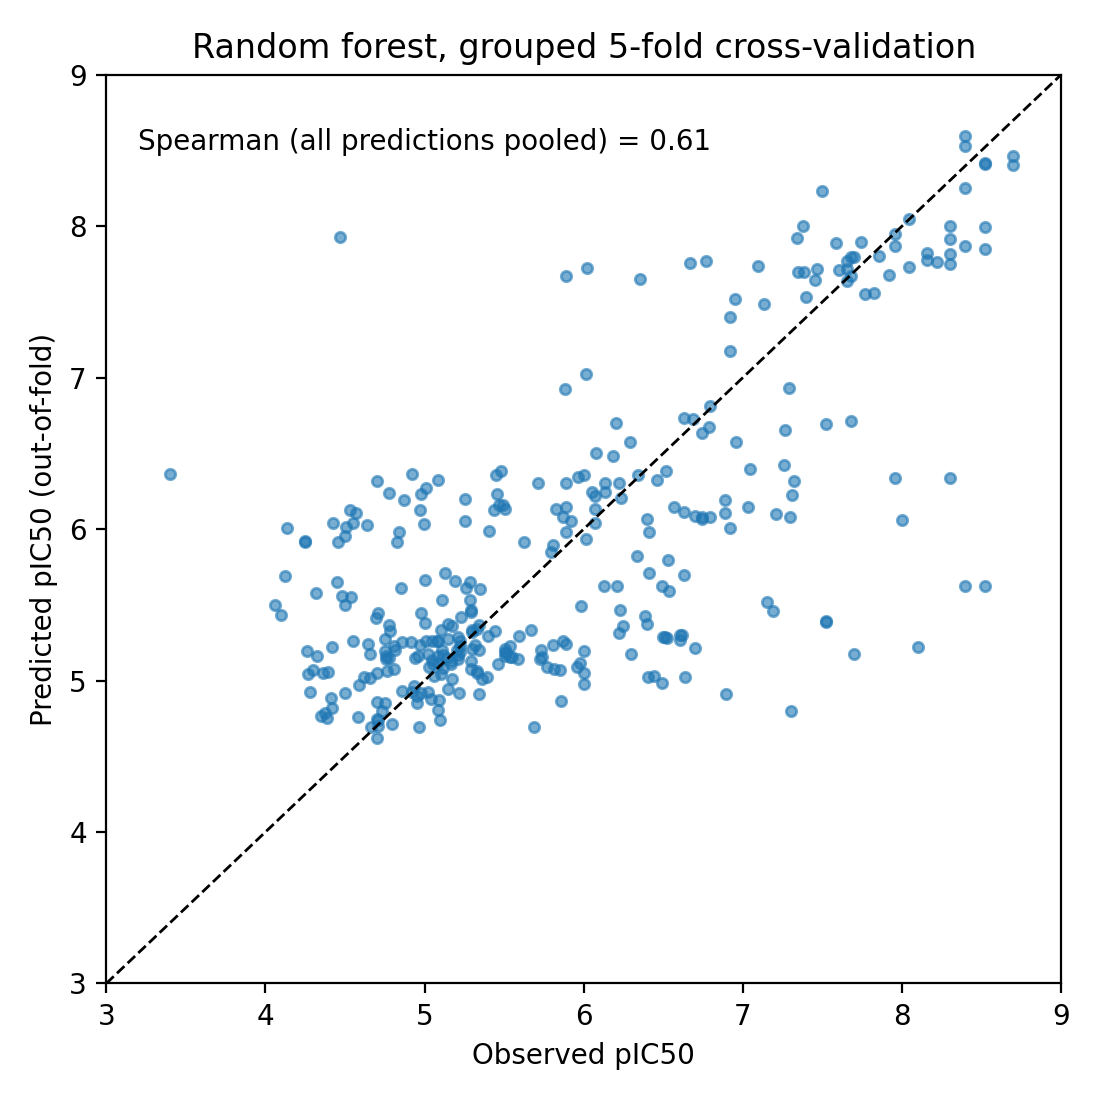

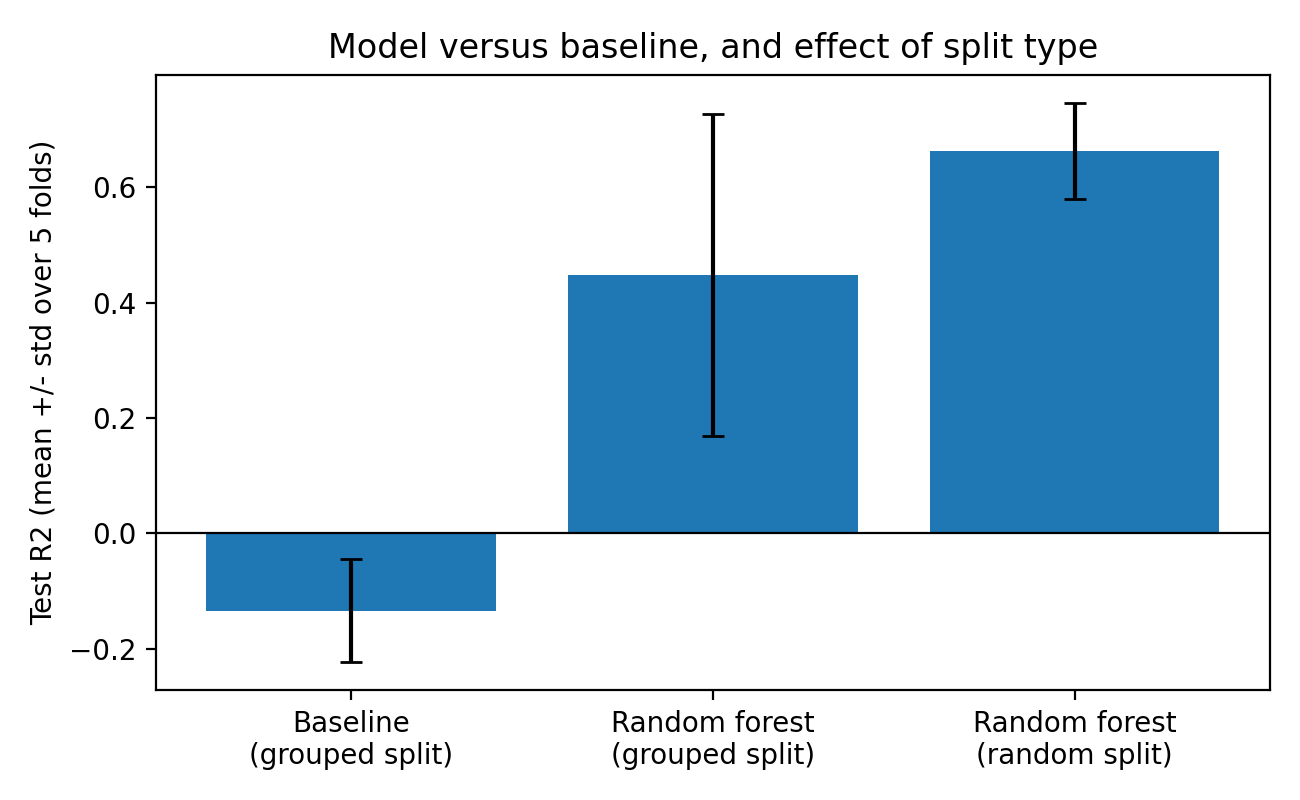

In [10]:
import matplotlib.pyplot as plt
oofd = pd.read_csv("oof_predictions_grouped.csv")
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(oofd.observed_pIC50, oofd.predicted_pIC50, s=14, alpha=0.6)
lims = [3, 9]
ax.plot(lims, lims, "k--", lw=1); ax.set_xlim(lims); ax.set_ylim(lims)
rho = spearmanr(oofd.observed_pIC50, oofd.predicted_pIC50)[0]
ax.text(3.2, 8.5, f"Spearman (all predictions pooled) = {rho:.2f}")
ax.set_xlabel("Observed pIC50"); ax.set_ylabel("Predicted pIC50 (out-of-fold)")
ax.set_title("Random forest, grouped 5-fold cross-validation")
fig.tight_layout(); fig.savefig("observed_vs_predicted_grouped.png", dpi=200); plt.close(fig)

m = pd.read_csv("rf_baseline_metrics_grouped.csv")
t = m[m.part == "test"].groupby(["split", "model"])["R2"].agg(["mean", "std"]).reset_index()
order = [("grouped", "baseline"), ("grouped", "random_forest"), ("random", "random_forest")]
names = ["Baseline\n(grouped split)", "Random forest\n(grouped split)", "Random forest\n(random split)"]
vals = [t[(t.split == s) & (t.model == mo)]["mean"].iloc[0] for s, mo in order]
errs = [t[(t.split == s) & (t.model == mo)]["std"].iloc[0] for s, mo in order]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(names, vals, yerr=errs, capsize=4)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("Test R2 (mean +/- std over 5 folds)")
ax.set_title("Model versus baseline, and effect of split type")
fig.tight_layout(); fig.savefig("model_comparison.png", dpi=200); plt.close(fig)

from IPython.display import Image, display
display(Image("observed_vs_predicted_grouped.png"))
display(Image("model_comparison.png"))

## 10. Record package versions

In [11]:
import sys, rdkit, sklearn, scipy, matplotlib as mpl
with open("requirements.txt", "w") as f:
    f.write(f"# Python {sys.version.split()[0]}\n")
    for name, v in [("rdkit", rdkit.__version__), ("scikit-learn", sklearn.__version__),
                    ("pandas", pd.__version__), ("numpy", np.__version__),
                    ("scipy", scipy.__version__), ("matplotlib", mpl.__version__)]:
        f.write(f"{name}=={v}\n")
print(open("requirements.txt").read())

# Python 3.13.16
rdkit==2026.03.6
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.1.3
scipy==1.16.3
matplotlib==3.10.0

